# Predictive Maintenance, Week 2: sequential deep learning models

Starting point: the week-1 pipeline (`week1_predictive_maintenance.ipynb`). The split is the same one: raw rows are assigned to train / validation / test by timestamp first, and every statistic used here (normalisation, class weights, thresholds) is computed on the training split, or chosen on validation. The test split is not opened.

Reusable code (window store, architectures, losses, training loop and metrics) lives in `pm_dl.py`.

In [1]:
import os, sys, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import optuna
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

sys.path.insert(0, '.')
from pm_dl import *

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid')
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))

QUICK = os.environ.get('PM_QUICK', '0') == '1'   # smoke-test mode: tiny budgets
DATA_DIR, OUT_DIR = 'archive', os.path.join('data', 'processed')
FIG_DIR = os.path.join('figures', 'week2'); os.makedirs(FIG_DIR, exist_ok=True)
T_VAL = pd.Timestamp('2015-09-01'); TRAIN_END = T_VAL - pd.Timedelta(hours=24)

telemetry = pd.read_csv(os.path.join(DATA_DIR, 'PdM_telemetry.csv'), parse_dates=['datetime'])
errors = pd.read_csv(os.path.join(DATA_DIR, 'PdM_errors.csv'), parse_dates=['datetime'])
maint = pd.read_csv(os.path.join(DATA_DIR, 'PdM_maint.csv'), parse_dates=['datetime'])
failures = pd.read_csv(os.path.join(DATA_DIR, 'PdM_failures.csv'), parse_dates=['datetime'])
machines = pd.read_csv(os.path.join(DATA_DIR, 'PdM_machines.csv'))

# Week-1 splits (rows, labels and week-1 features). The test parquet is not loaded.
train_df = pd.read_parquet(os.path.join(OUT_DIR, 'train.parquet'))
val_df = pd.read_parquet(os.path.join(OUT_DIR, 'validation.parquet'))
print('train', train_df.shape, 'validation', val_df.shape, '| QUICK =', QUICK)

# Every trained run is cached (validation predictions + learning curve) so that re-running the notebook
# does not retrain unchanged experiments. Delete runs/week2 to retrain from scratch.
RUN_DIR = os.path.join('runs', 'week2' + ('_quick' if QUICK else '')); os.makedirs(RUN_DIR, exist_ok=True)
def cached_run(name, fit_fn):
    f = os.path.join(RUN_DIR, name.replace(' ', '_').replace('=', '').replace('(', '').replace(')', '') + '.npz')
    if os.path.exists(f):
        z = np.load(f, allow_pickle=True)
        return z['pb'], z['pm'], pd.DataFrame(z['hist'].item()), float(z['minutes'])
    t0 = time.time()
    pb, pm, hist = fit_fn()
    minutes = (time.time() - t0) / 60
    np.savez_compressed(f, pb=pb, pm=pm, hist=hist.to_dict(orient='list'), minutes=minutes)
    return pb, pm, hist, minutes

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train (580200, 41) validation (144000, 41) | QUICK = False


## 2.1 Input tensor

For every machine `m` and hour `t`, the input is a window of the last `L` hours, `(t-L, t]`, with `L ∈ {24, 72, 168}`, and 13 dynamic channels:

| Channels | Content |
|---|---|
| 4 | `volt, rotate, pressure, vibration`, standardised |
| 5 | hourly indicator of each error type (`error1`–`error5`) logged at that hour |
| 4 | `log(1 + hours since the last replacement)` of each component, using records strictly before the hour |

Static inputs: an embedding (dimension 3) of the machine model and the standardised age.

**Normalisation.** Global z-score per channel, with means and standard deviations computed only on training-period hours (`t < 2015-08-31`). Week 1 showed that the four models share the same sensor distributions, so a per-model normalisation adds nothing, and the model identity is still given by the embedding. Per-machine normalisation was rejected because each machine's statistics would have to come from its own history, and with one year per machine that history overlaps validation; it would also erase level differences between machines that may matter. Hours since replacement are log-transformed because they are heavy-tailed (0 to several thousand hours). Hours with no previous replacement get the training mean (0 after standardisation).

Windows are cut on demand from one flat array of normalised hourly channels, so the 580,200 training windows of 168 h are never materialised (that would be about 5 GB). A window at the start of a split looks back into earlier hours; that history is in the past, so it is allowed (same rule as the 24 h context of week 1). Windows that would start before 1 Jan 2015 repeat the first hour.

,mean (train),std (train)
volt,170.809,15.512
rotate,446.577,52.643
pressure,100.811,11.014
vibration,40.393,5.366
error1_now,0.001,0.034
error2_now,0.001,0.033
error3_now,0.001,0.031
error4_now,0.001,0.028
error5_now,0.000,0.020
log_hours_since_comp1,6.556,1.331


L= 24: dynamic tensor (4, 24, 13) (batch, L, channels); static: model id (4,), age (4, 1)
L= 72: dynamic tensor (4, 72, 13) (batch, L, channels); static: model id (4,), age (4, 1)
L=168: dynamic tensor (4, 168, 13) (batch, L, channels); static: model id (4,), age (4, 1)


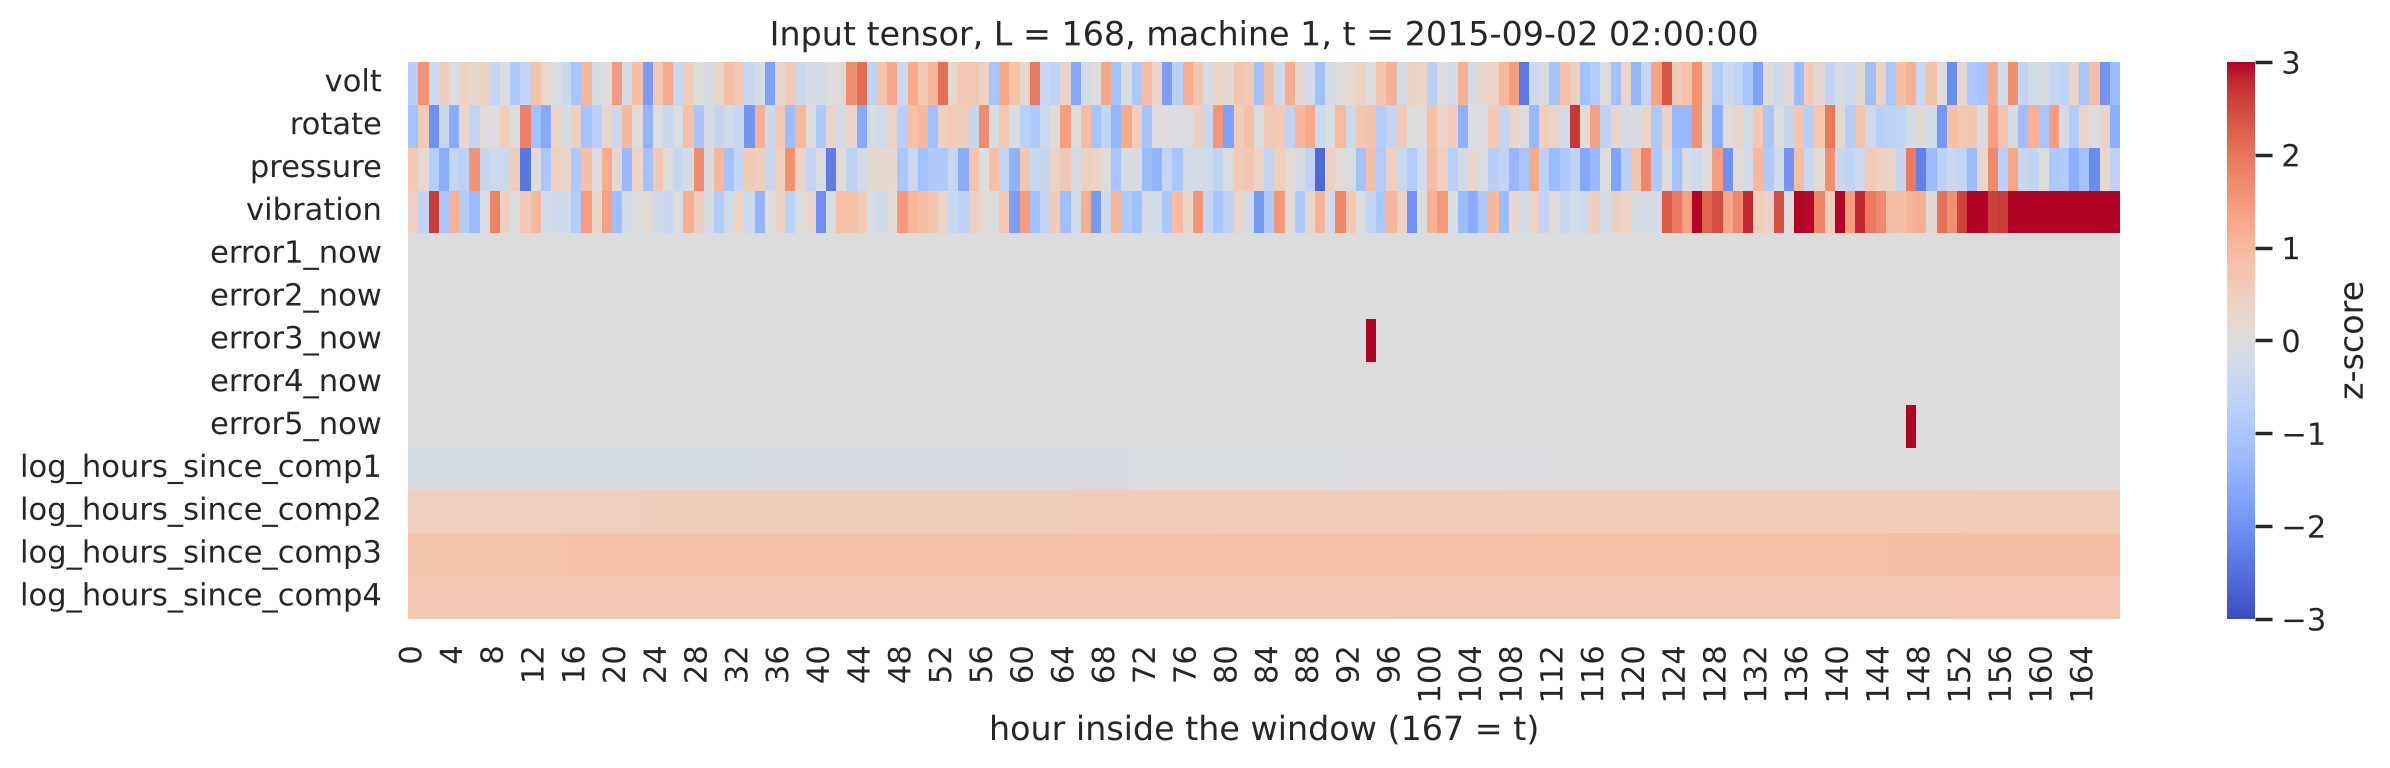

In [2]:
grid = build_hourly_channels(telemetry, errors, maint)
norm_stats = norm_stats_from_train(grid, TRAIN_END)
store = SequenceStore(grid, machines, norm_stats)
age_stats = (train_df['age'].mean(), train_df['age'].std())
TR = SplitData(train_df, store, age_stats)
VA = SplitData(val_df, store, age_stats)
val_meta = VA.df[['machineID', 'datetime']]

display(pd.DataFrame({'mean (train)': norm_stats[0], 'std (train)': norm_stats[1]}, index=CHANNELS).round(3))
for L in (24, 72, 168):
    x, m, a, yb, ym = TR.batch(np.arange(4), L)
    print(f'L={L:3d}: dynamic tensor {tuple(x.shape)} (batch, L, channels); static: model id {tuple(m.shape)}, age {tuple(a.shape)}')

# A pre-failure window, to see the tensor
row = VA.df[(VA.df['y_binary'] == 1)].iloc[0]
i = int(VA.df.index[(VA.df['machineID'] == row.machineID) & (VA.df['datetime'] == row.datetime + pd.Timedelta(hours=20))][0]) \
    if ((VA.df['machineID'] == row.machineID) & (VA.df['datetime'] == row.datetime + pd.Timedelta(hours=20))).any() else int(VA.df.index[0])
x, *_ = VA.batch(np.array([i]), 168)
fig, ax = plt.subplots(figsize=(13, 4))
sns.heatmap(x[0].numpy().T, cmap='coolwarm', center=0, vmin=-3, vmax=3, yticklabels=CHANNELS, ax=ax, cbar_kws={'label': 'z-score'})
ax.set_xlabel('hour inside the window (167 = t)'); ax.set_title(f'Input tensor, L = 168, machine {VA.df.machineID[i]}, t = {VA.df.datetime[i]}')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'tensor_example.png'), dpi=160); plt.show()

## 2.2 Architectures

All three share the static encoder (model embedding + age) and the same two heads on top of a shared dense layer (64 units, ReLU, dropout): a binary logit (failure in the next 24 h) and five class logits (`none, comp1..comp4`).

* **LSTM**: one LSTM layer (64 units, two layers explored by Optuna); static inputs concatenated to the final hidden state.
* **TCN**: residual blocks of two causal dilated convolutions (kernel 3, 32 channels); dilations 1, 2, 4, ... are added until the receptive field covers `L` (3 blocks for 24 h, 5 for 72 h, 6 for 168 h). The output at the last time step is used.
* **CNN-LSTM**: two causal convolutions (kernel 5, 32 channels) and max-pooling by 2 extract local patterns and halve the length; an LSTM (64 units) summarises the shorter sequence.

**Combined loss.** `loss = L_binary + λ · L_multiclass`, with `λ = 0.5`. The binary head is the decision that triggers maintenance and carries the early-stopping metric, so it gets the larger weight. The multiclass loss has five classes and starts at about `ln 5 ≈ 1.6` against `ln 2 ≈ 0.7` for the binary one, so `λ = 0.5` keeps both terms on a similar scale at the start, and the shared representation still learns component-specific patterns. λ is also one of the hyper-parameters searched by Optuna.

**Component decision.** The binary head decides whether to alert (threshold chosen on validation, as in week 1) and, when it alerts, the multiclass head chooses the component (argmax over `comp1..comp4`). The direct argmax of the multiclass head is also reported.

In [3]:
rows = []
for arch in ['LSTM', 'TCN', 'CNN-LSTM']:
    for L in (24, 72, 168):
        m = make_model(arch, L)
        rows.append({'architecture': arch, 'L': L, 'parameters': sum(p.numel() for p in m.parameters()),
                     'receptive field (h)': getattr(m, 'receptive_field', L)})
display(pd.DataFrame(rows).pivot(index='architecture', columns='L', values='parameters'))
print(make_model('TCN', 168))

L,24,72,168
architecture,,,
CNN-LSTM,37170,37170,37170
LSTM,25042,25042,25042
TCN,20018,32434,38642


TCNNet(
  (tcn): Sequential(
    (0): CausalConvBlock(
      (conv1): Conv1d(13, 32, kernel_size=(3,), stride=(1,))
      (conv2): Conv1d(32, 32, kernel_size=(3,), stride=(1,))
      (drop): Dropout(p=0.2, inplace=False)
      (res): Conv1d(13, 32, kernel_size=(1,), stride=(1,))
    )
    (1): CausalConvBlock(
      (conv1): Conv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(2,))
      (conv2): Conv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(2,))
      (drop): Dropout(p=0.2, inplace=False)
      (res): Identity()
    )
    (2): CausalConvBlock(
      (conv1): Conv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(4,))
      (conv2): Conv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(4,))
      (drop): Dropout(p=0.2, inplace=False)
      (res): Identity()
    )
    (3): CausalConvBlock(
      (conv1): Conv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(8,))
      (conv2): Conv1d(32, 32, kernel_size=(3,), stride=(1,), dilation=(8,))
      (drop): Dropout(p=0.2, inp

## Week-1 baselines on the same validation set

Logistic regression and XGBoost are refitted exactly as in week 1 (same features, same pre-processing fitted on train) so that they can be scored with the same functions as the networks: PR-AUC, recall at precision ≥ 0.80, F1 macro per component and anticipation time.

**Anticipation time.** For every validation failure event: hours between the start of the first *sustained* alert (probability above the validation threshold for at least 3 consecutive hours) and the failure. The alert is searched in the 72 h before the failure, three times the label horizon, so that an alert raised earlier than 24 h ahead still counts (with a 24 h search window every model would score exactly 24 h). Events without a sustained alert count as missed.

In [4]:
LABELS = ['y_comp1', 'y_comp2', 'y_comp3', 'y_comp4', 'y_binary', 'y_multiclass', 'n_components_in_window']
feat_cols = [c for c in train_df.columns if c not in LABELS + ['machineID', 'datetime']]
num_cols = [c for c in feat_cols if c != 'model']
def prep():
    return ColumnTransformer([('n', Pipeline([('i', SimpleImputer(strategy='median')), ('s', StandardScaler())]), num_cols),
                              ('c', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['model'])])
tr_s = train_df.sort_values(['machineID', 'datetime']).reset_index(drop=True)
va_s = val_df.sort_values(['machineID', 'datetime']).reset_index(drop=True)
ytr, ytr_mc = tr_s['y_binary'].values, tr_s['y_multiclass'].values
XGBP = dict(n_estimators=150, max_depth=4, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8, tree_method='hist', n_jobs=-1, random_state=SEED)
spw = (ytr == 0).sum() / ytr.sum()

baselines = {}
t0 = time.time()
xb = Pipeline([('p', prep()), ('m', XGBClassifier(objective='binary:logistic', scale_pos_weight=spw, **XGBP))]).fit(tr_s[feat_cols], ytr)
xm = Pipeline([('p', prep()), ('m', XGBClassifier(objective='multi:softprob', **XGBP))]).fit(
    tr_s[feat_cols], ytr_mc, m__sample_weight=compute_sample_weight('balanced', ytr_mc))
baselines['XGBoost (week 1)'] = (xb.predict_proba(va_s[feat_cols])[:, 1], xm.predict_proba(va_s[feat_cols]))
lb_ = Pipeline([('p', prep()), ('m', LogisticRegression(class_weight='balanced', max_iter=500))]).fit(tr_s[feat_cols], ytr)
lm_ = Pipeline([('p', prep()), ('m', LogisticRegression(class_weight='balanced', max_iter=300))]).fit(tr_s[feat_cols], ytr_mc)
baselines['Logistic regression (week 1)'] = (lb_.predict_proba(va_s[feat_cols])[:, 1], lm_.predict_proba(va_s[feat_cols]))
print(f'baselines fitted in {time.time() - t0:.0f}s')
assert (va_s[['machineID', 'datetime']].values == VA.df[['machineID', 'datetime']].values).all()

results, leads = [], {}
for name, (pb, pm) in baselines.items():
    r, lead = evaluate(name, VA.yb, VA.ym, pb, pm, val_meta, failures)
    r['F1_macro_comp_direct'] = f1_score(VA.ym, pm.argmax(1), labels=[1, 2, 3, 4], average='macro')
    results.append({**r, 'family': 'baseline', 'L': None, 'strategy': 'class weights'}); leads[name] = lead
display(pd.DataFrame(results).set_index('model')[['PR-AUC', 'recall', 'FP', 'F1_macro_comp', 'F1_macro_comp_direct', 'events_alerted_%', 'lead_median_h']].round(3))

baselines fitted in 69s


,PR-AUC,recall,FP,F1_macro_comp,F1_macro_comp_direct,events_alerted_%,lead_median_h
model,,,,,,,
XGBoost (week 1),0.998,1.000,662,0.875,0.993,100.00,24.0
Logistic regression (week 1),0.853,0.804,533,0.770,0.750,93.75,24.0


## 2.2 / 2.4 Architecture × window length

Every network is trained with the same disciplined loop (each run is cached in `runs/week2/`):

* AdamW (learning rate 2e-3, weight decay 1e-4), dropout 0.2, gradient clipping at 1.0, batch 512;
* imbalance strategy for this comparison: **undersampling** of healthy hours (every positive training hour + 4 random healthy hours per positive, redrawn each epoch, about 58,700 windows per epoch);
* **early stopping on validation PR-AUC** of the binary head (patience 3, at most 12 epochs); the best epoch is restored. To keep the cost of each epoch bounded, the stopping metric is computed on every third validation hour (48,000 windows, same prevalence); all reported metrics use the full validation set.

In [5]:
EPOCHS, PATIENCE = (2, 1) if QUICK else (12, 3)
ARCHS = ['LSTM', 'TCN', 'CNN-LSTM']
WINDOWS = (24, 72) if QUICK else (24, 72, 168)
val_es_idx = np.arange(0, len(VA), 3)
histories, preds = {}, {}

for L in WINDOWS:
    for arch in ARCHS:
        name = f'{arch} L={L}'
        print(name, flush=True)
        def fit(arch=arch, L=L):
            strat = Strategy('undersample', TR.yb, TR.ym, epoch_size=60000, neg_ratio=4, seed=SEED)
            model, hist = train_model(arch, L, TR, VA, strat, epochs=EPOCHS, patience=PATIENCE, val_idx=val_es_idx, seed=SEED)
            return (*predict(model, VA, L), hist)
        pb, pm, hist, minutes = cached_run(name, fit)
        r, lead = evaluate(name, VA.yb, VA.ym, pb, pm, val_meta, failures)
        r.update({'family': 'deep learning', 'architecture': arch, 'L': L, 'strategy': 'undersample',
                  'epochs_run': len(hist), 'best_epoch': int(hist['val_pr_auc'].idxmax()) + 1, 'train_minutes': minutes})
        results.append(r); histories[name] = hist; preds[name] = (pb, pm); leads[name] = lead
        print(f'  -> PR-AUC {r["PR-AUC"]:.4f}  recall@P0.8 {r["recall"]:.3f}  F1 comp {r["F1_macro_comp"]:.3f}  ({r["train_minutes"]:.1f} min)', flush=True)

res = pd.DataFrame(results)
grid_res = res[res['family'] == 'deep learning']
display(grid_res.pivot(index='architecture', columns='L', values='PR-AUC').round(4))

LSTM L=24


  ep  1 loss 0.3974  val PR-AUC 0.9753  (3s)


  ep  2 loss 0.0474  val PR-AUC 0.9874  (3s)


  ep  3 loss 0.0267  val PR-AUC 0.9888  (3s)


  ep  4 loss 0.0192  val PR-AUC 0.9897  (4s)


  ep  5 loss 0.0179  val PR-AUC 0.9916  (3s)


... (104 outputs left out)

  ep 10 loss 0.0137  val PR-AUC 0.9965  (19s)


  ep 11 loss 0.0129  val PR-AUC 0.9940  (18s)


  -> PR-AUC 0.9982  recall@P0.8 1.000  F1 comp 0.879  (3.6 min)


L,24.0,72.0,168.0
architecture,,,
CNN-LSTM,0.9979,0.9951,0.9982
LSTM,0.9966,0.9915,0.9927
TCN,0.9989,0.9989,0.9993


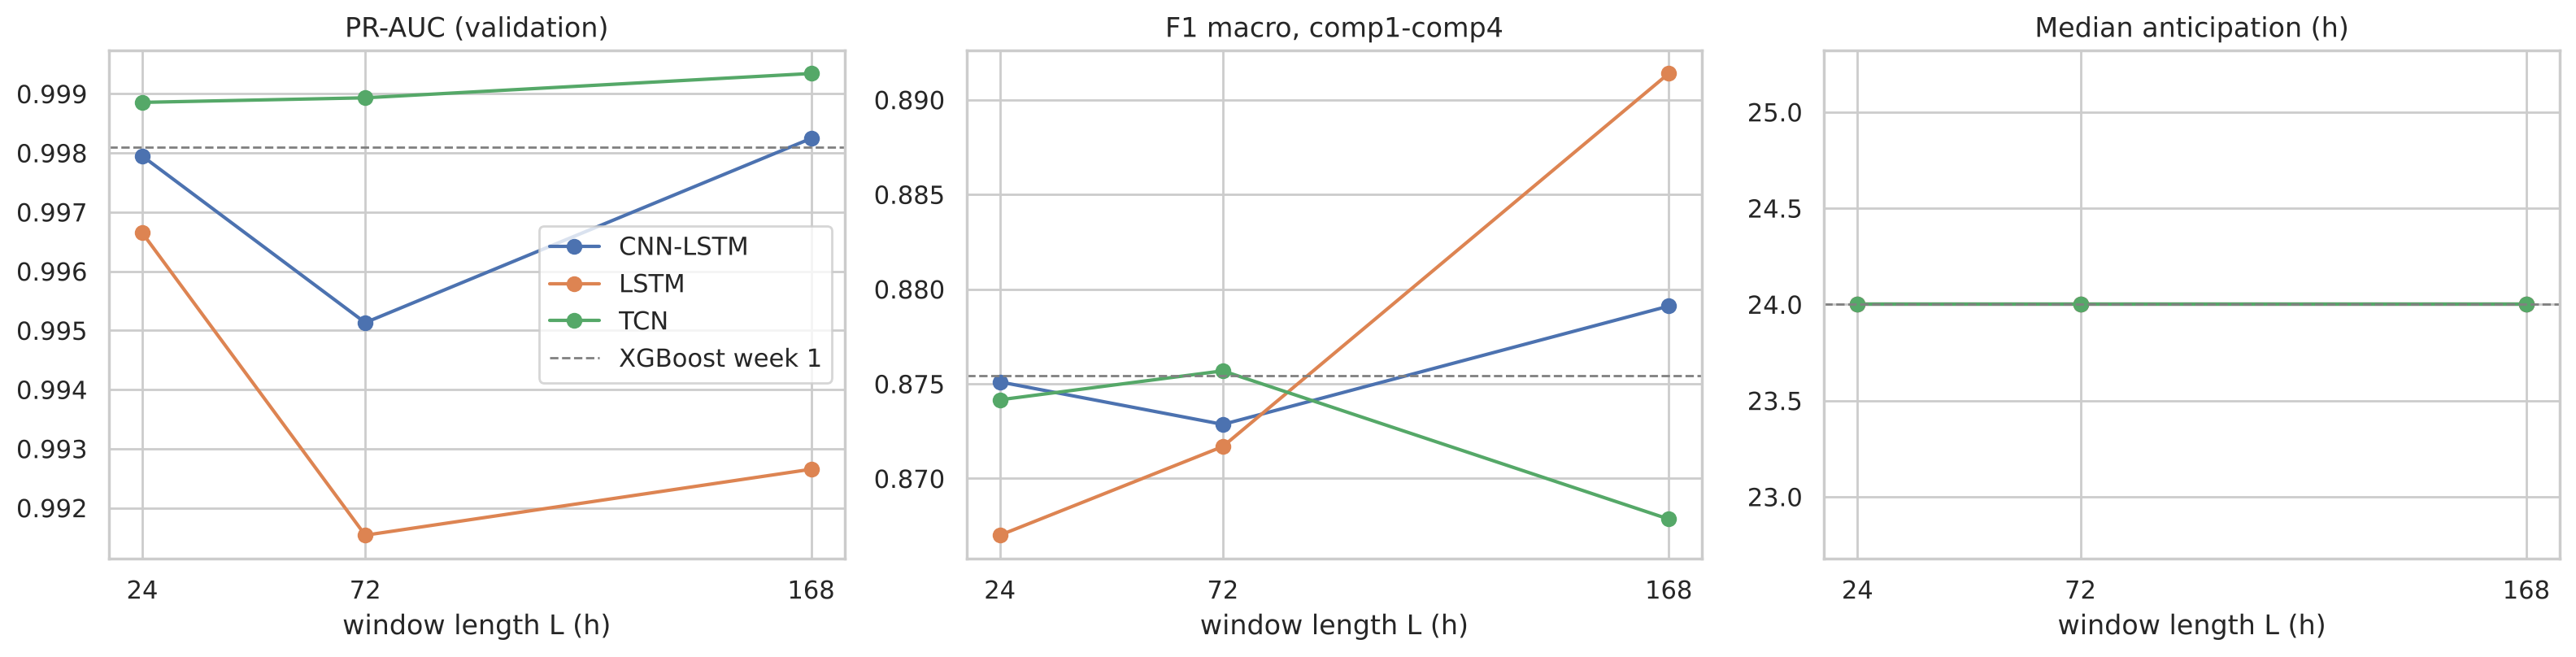

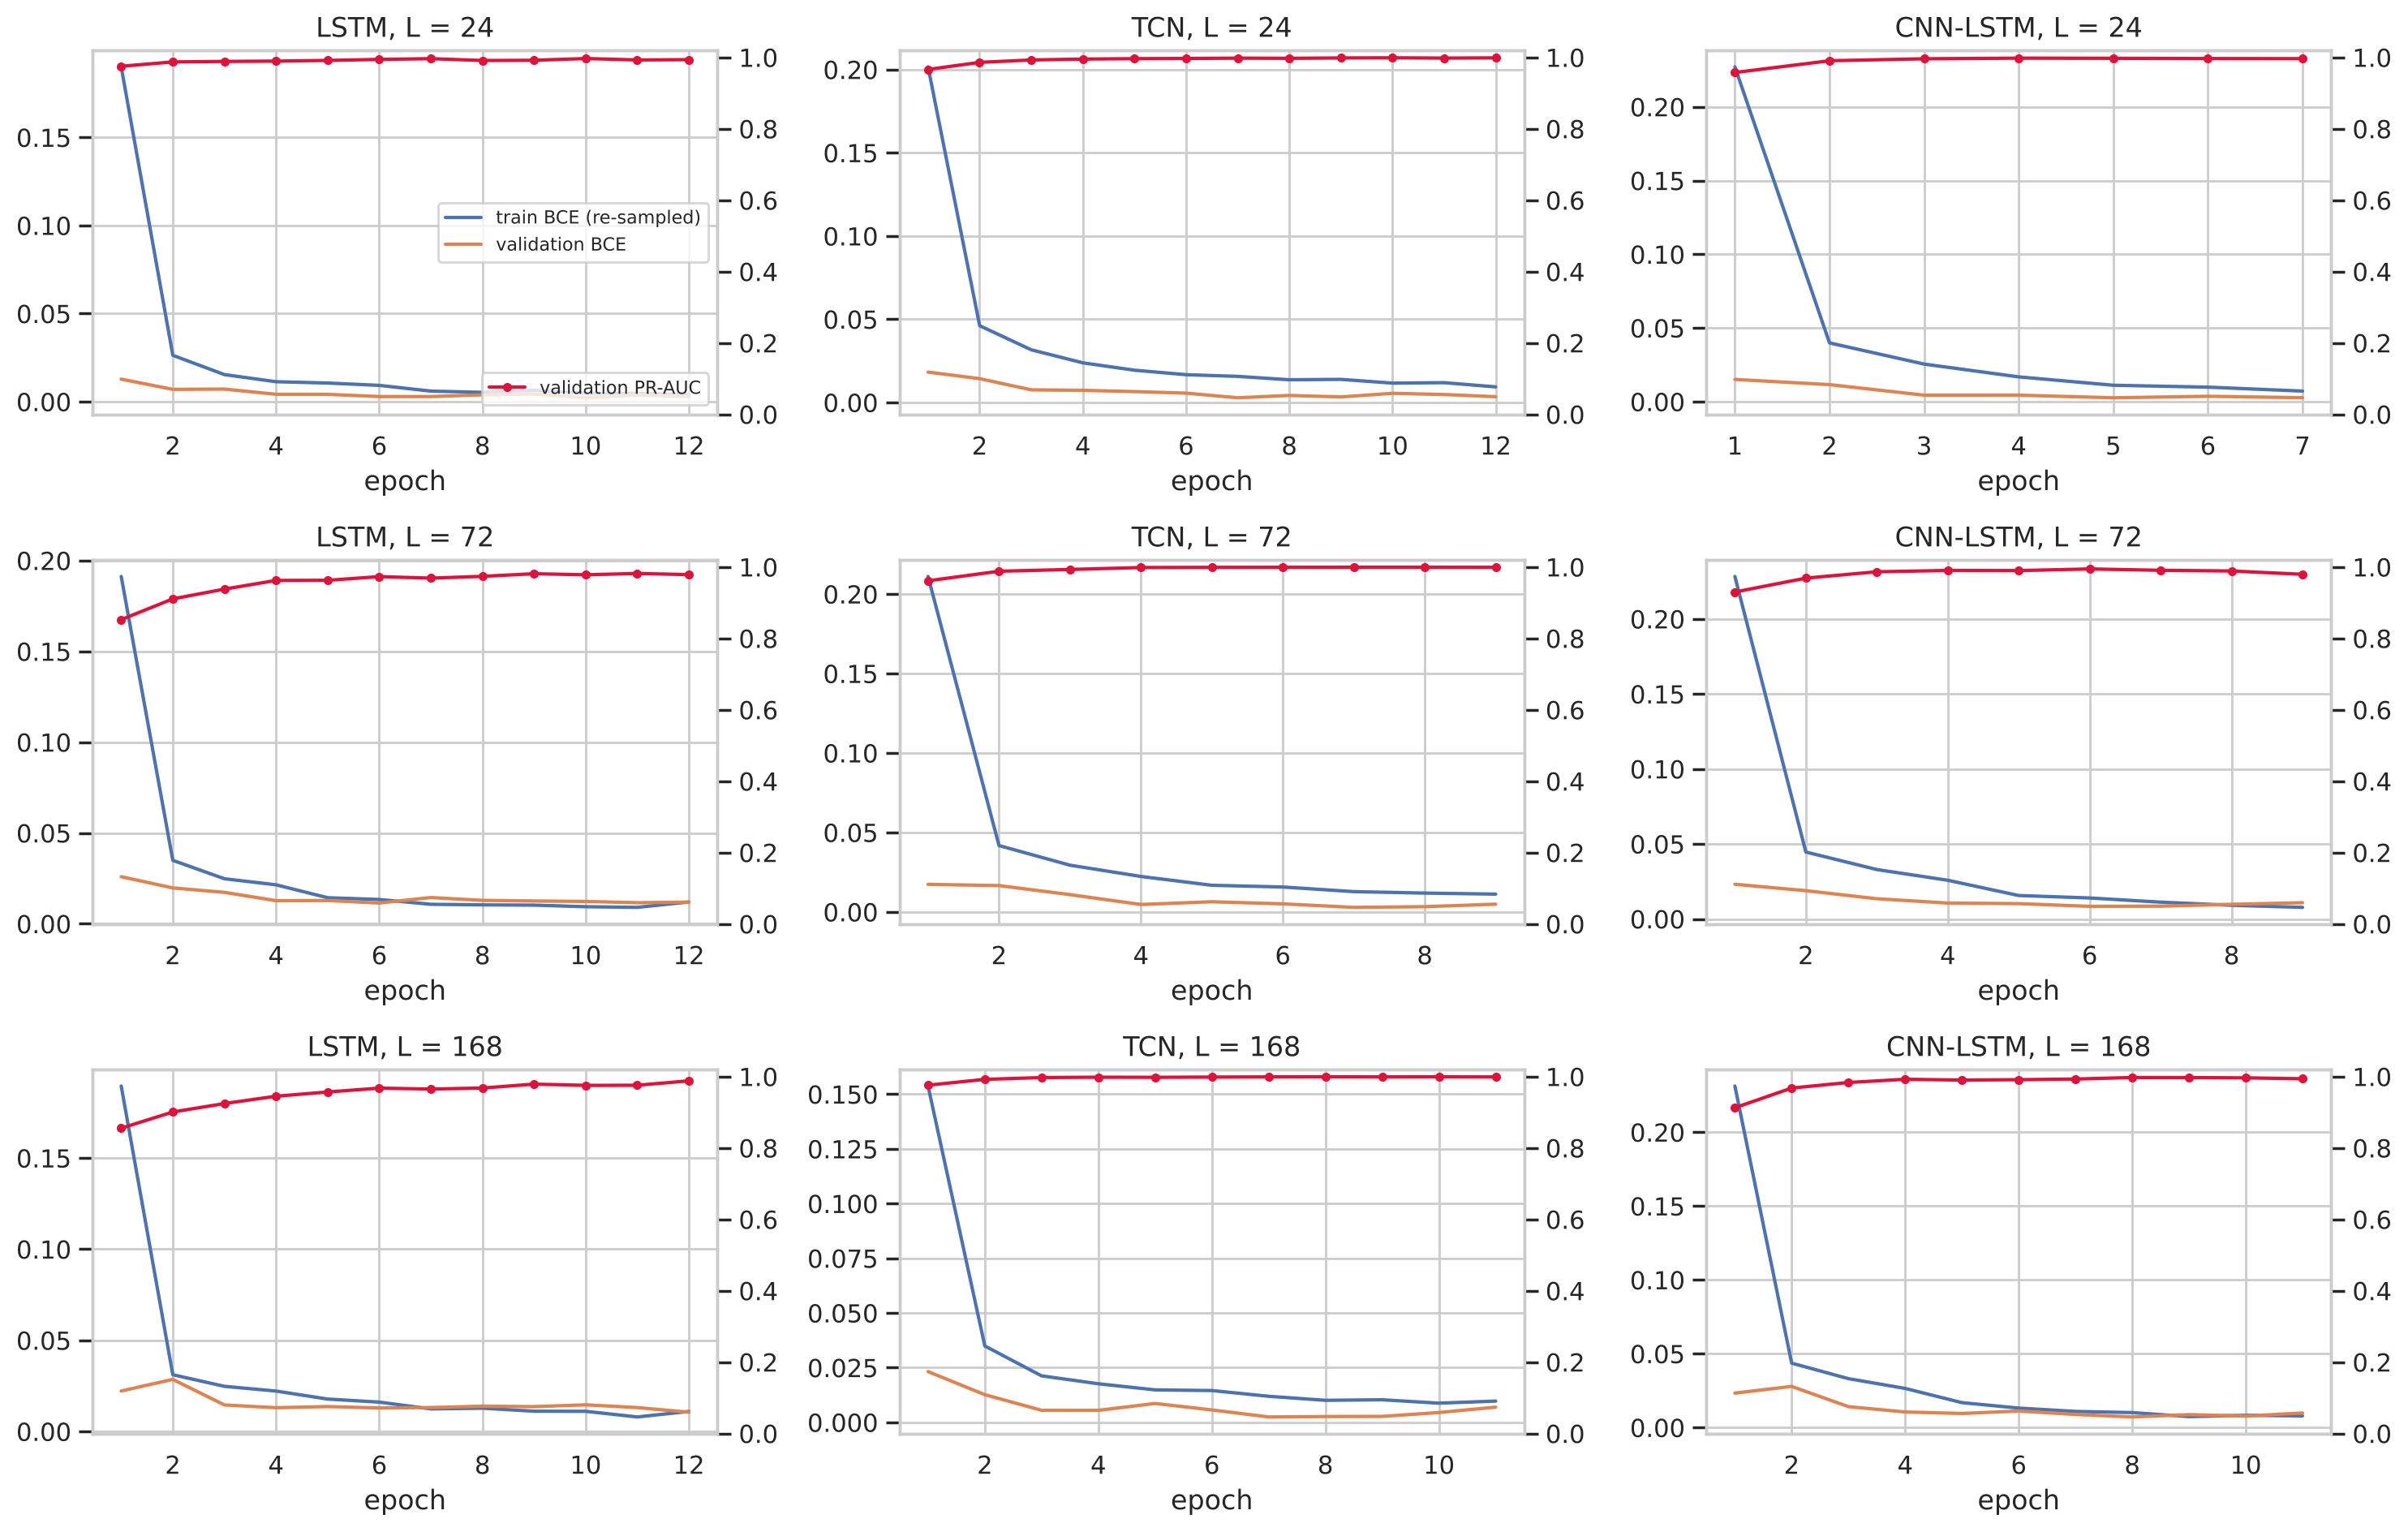

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for arch, g in grid_res.groupby('architecture'):
    axes[0].plot(g['L'], g['PR-AUC'], marker='o', label=arch)
    axes[1].plot(g['L'], g['F1_macro_comp'], marker='o', label=arch)
    axes[2].plot(g['L'], g['lead_median_h'], marker='o', label=arch)
xgb_row = res[res['model'] == 'XGBoost (week 1)'].iloc[0]
for ax, col, title in zip(axes, ['PR-AUC', 'F1_macro_comp', 'lead_median_h'], ['PR-AUC (validation)', 'F1 macro, comp1-comp4', 'Median anticipation (h)']):
    ax.axhline(xgb_row[col], color='grey', ls='--', lw=1, label='XGBoost week 1')
    ax.set_xticks(list(WINDOWS)); ax.set_xlabel('window length L (h)'); ax.set_title(title)
axes[0].legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'effect_of_L.png'), dpi=160); plt.show()

fig, axes = plt.subplots(len(WINDOWS), len(ARCHS), figsize=(15, 3.2 * len(WINDOWS)), squeeze=False)
for i, L in enumerate(WINDOWS):
    for j, arch in enumerate(ARCHS):
        h = histories[f'{arch} L={L}']; ax = axes[i, j]
        ax.plot(h['epoch'], h['train_bce'], label='train BCE (re-sampled)')
        ax.plot(h['epoch'], h['val_bce'], label='validation BCE')
        ax2 = ax.twinx(); ax2.plot(h['epoch'], h['val_pr_auc'], color='crimson', marker='.', label='validation PR-AUC'); ax2.set_ylim(0, 1.02); ax2.grid(False)
        ax.set_title(f'{arch}, L = {L}'); ax.set_xlabel('epoch')
        if i == 0 and j == 0:
            ax.legend(loc='center right', fontsize=8); ax2.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'learning_curves.png'), dpi=140); plt.show()

## 2.3 Class imbalance

The best architecture / window of the previous grid is retrained with three more strategies (the undersampling run is reused):

| Strategy | Sampling per epoch | Binary loss |
|---|---|---|
| weighted loss | 60,000 random hours (natural 2 % prevalence) | BCE with `pos_weight = n_neg / n_pos ≈ 48`; class-weighted CE |
| focal loss | 60,000 random hours | focal loss, γ = 2, α = 0.75; class-weighted CE |
| undersampling | all positives + 4 healthy per positive (20 % prevalence) | plain BCE / CE |
| oversampling | 60,000 random hours + every pre-failure window repeated 5 times | plain BCE / CE |

Calibration is measured with the Brier score and the expected calibration error (ECE, 15 quantile bins) on validation. Re-sampling changes the class prior the network sees (20 % instead of 2 %), so its probabilities are shifted upwards; the prior-correction `odds' = odds · (π / (1-π)) / (π_s / (1-π_s))` maps them back to the true prevalence `π`. Rankings (PR-AUC) and therefore any threshold-based metric are unaffected by that monotone correction.

,model,PR-AUC,train_minutes
3,TCN L=24,0.9989,1.5307
6,TCN L=72,0.9989,5.0820
9,TCN L=168,0.9993,16.4785


selected for the next experiments: TCN L = 24
TCN L=24 weighted


  ep  1 loss 1.1698  val PR-AUC 0.9205  (6s)


  ep  2 loss 0.3210  val PR-AUC 0.9627  (6s)


  ep  3 loss 0.2548  val PR-AUC 0.9834  (6s)


  ep  4 loss 0.2200  val PR-AUC 0.9875  (6s)


... (29 outputs left out)

  ep  7 loss 0.0143  val PR-AUC 0.9988  (13s)


  ep  8 loss 0.0123  val PR-AUC 0.9982  (13s)


  ep  9 loss 0.0108  val PR-AUC 0.9985  (14s)


  -> PR-AUC 0.9993  recall@P0.8 1.000  ECE 0.0013


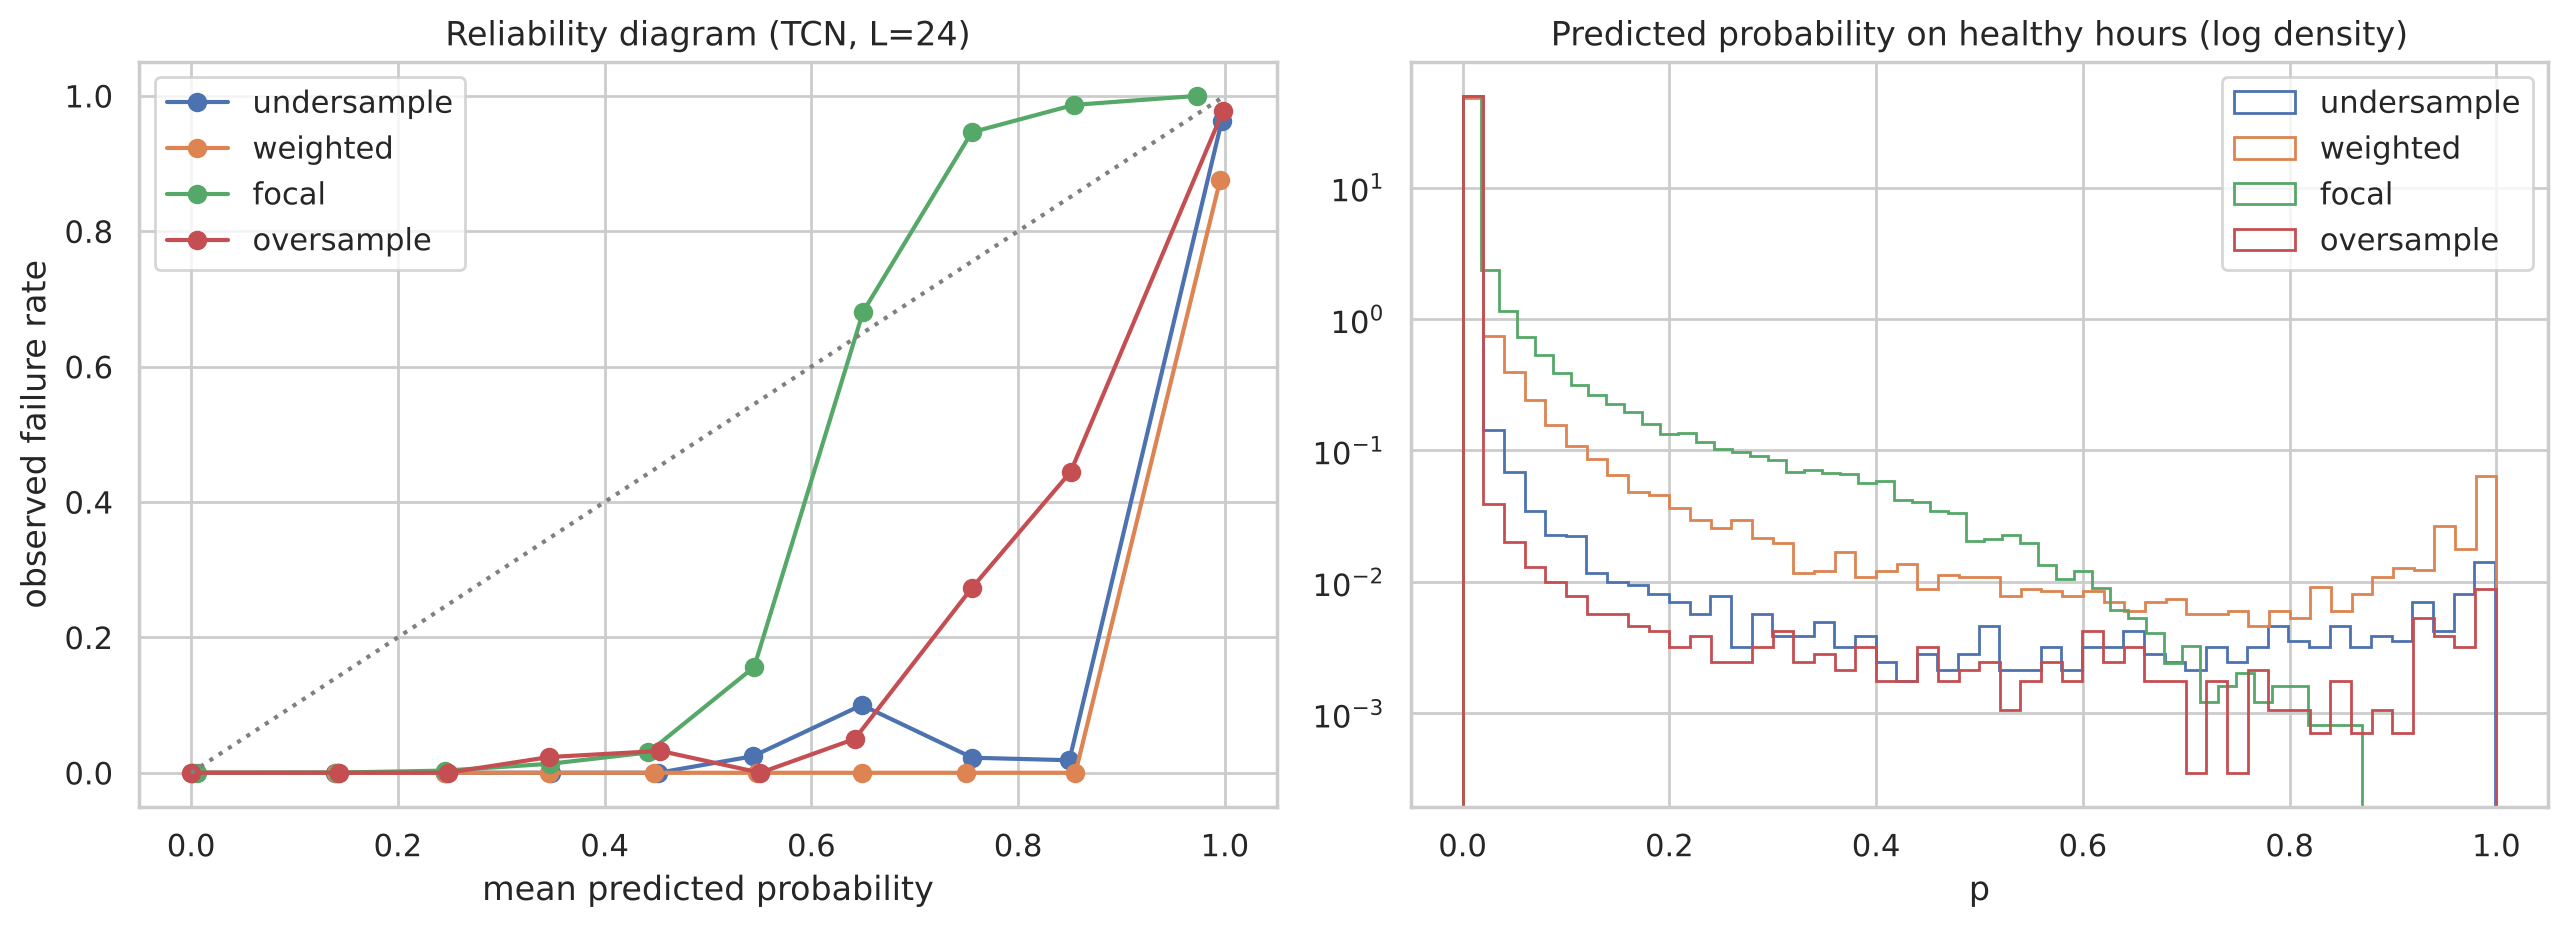

true validation prevalence = 0.0184


,train positive rate,PR-AUC,recall@P0.8,F1 macro comp,mean p (val),Brier,ECE,Brier (prior-corrected),ECE (prior-corrected)
strategy,,,,,,,,,
undersample,0.2000,0.9989,1.000,0.8742,0.0209,0.0015,0.0025,0.0005,0.0005
weighted,0.0202,0.9952,1.000,0.8741,0.0274,0.0047,0.0090,NaN,NaN
focal,0.0202,0.9915,0.991,0.8736,0.0327,0.0044,0.0143,NaN,NaN
oversample,0.5048,0.9993,1.000,0.8738,0.0197,0.0008,0.0013,0.0004,0.0005


In [7]:
# Selection rule: highest validation PR-AUC; configurations within 0.001 of the best are treated as tied
# (well inside run-to-run noise with ~112 failure events) and the cheapest one (shortest window) is kept.
top = grid_res['PR-AUC'].max()
tied = grid_res[grid_res['PR-AUC'] >= top - 0.001].sort_values(['L', 'PR-AUC'], ascending=[True, False])
display(tied[['model', 'PR-AUC', 'train_minutes']].round(4))
best_row = tied.iloc[0]
BEST_ARCH, BEST_L = best_row['architecture'], int(best_row['L'])
print('selected for the next experiments:', BEST_ARCH, 'L =', BEST_L)

strategy_runs = {'undersample': f'{BEST_ARCH} L={BEST_L}'}
strategy_objs = {'undersample': Strategy('undersample', TR.yb, TR.ym, 60000, neg_ratio=4, seed=SEED)}
for sname in ['weighted', 'focal', 'oversample']:
    name = f'{BEST_ARCH} L={BEST_L} {sname}'
    print(name, flush=True)
    strat = Strategy(sname, TR.yb, TR.ym, epoch_size=60000, rep=5, seed=SEED)
    strategy_objs[sname] = strat
    def fit(strat=strat):
        model, hist = train_model(BEST_ARCH, BEST_L, TR, VA, strat, epochs=EPOCHS, patience=PATIENCE, val_idx=val_es_idx, seed=SEED)
        return (*predict(model, VA, BEST_L), hist)
    pb, pm, hist, minutes = cached_run(name, fit)
    r, lead = evaluate(name, VA.yb, VA.ym, pb, pm, val_meta, failures)
    r.update({'family': 'deep learning', 'architecture': BEST_ARCH, 'L': BEST_L, 'strategy': sname,
              'epochs_run': len(hist), 'best_epoch': int(hist['val_pr_auc'].idxmax()) + 1, 'train_minutes': minutes})
    results.append(r); histories[name] = hist; preds[name] = (pb, pm); leads[name] = lead; strategy_runs[sname] = name
    print(f'  -> PR-AUC {r["PR-AUC"]:.4f}  recall@P0.8 {r["recall"]:.3f}  ECE {r["ECE"]:.4f}', flush=True)

res = pd.DataFrame(results)
cal_rows = []
true_rate = VA.yb.mean()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for sname, run in strategy_runs.items():
    pb = preds[run][0]; strat = strategy_objs[sname]
    r = res[res['model'] == run].iloc[0]
    row = {'strategy': sname, 'train positive rate': strat.train_positive_rate(), 'PR-AUC': r['PR-AUC'], 'recall@P0.8': r['recall'],
           'F1 macro comp': r['F1_macro_comp'], 'mean p (val)': pb.mean(), 'Brier': brier_score_loss(VA.yb, pb), 'ECE': expected_calibration_error(VA.yb, pb)}
    if sname in ('undersample', 'oversample'):
        pc = prior_correct(pb, strat.train_positive_rate(), TR.yb.mean())
        row.update({'Brier (prior-corrected)': brier_score_loss(VA.yb, pc), 'ECE (prior-corrected)': expected_calibration_error(VA.yb, pc)})
    cal_rows.append(row)
    fr, mp = calibration_curve(VA.yb, pb, n_bins=10, strategy='uniform')
    ax[0].plot(mp, fr, marker='o', label=sname)
    ax[1].hist(pb[VA.yb == 0], bins=50, histtype='step', density=True, label=sname, log=True)
ax[0].plot([0, 1], [0, 1], color='grey', ls=':'); ax[0].set_xlabel('mean predicted probability'); ax[0].set_ylabel('observed failure rate')
ax[0].set_title(f'Reliability diagram ({BEST_ARCH}, L={BEST_L})'); ax[0].legend()
ax[1].set_title('Predicted probability on healthy hours (log density)'); ax[1].set_xlabel('p'); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'calibration.png'), dpi=160); plt.show()
calibration = pd.DataFrame(cal_rows).set_index('strategy')
print(f'true validation prevalence = {true_rate:.4f}')
display(calibration.round(4))

## 2.4 Hyper-parameter search (declared budget)

Optuna (TPE sampler, median pruner) on the best architecture and window, with the best imbalance strategy.

**Budget: 30 trials or 40 minutes of wall-clock time, whichever comes first**, at most 6 epochs per trial, pruning after the first epoch. Search space: learning rate (3e-4 to 5e-3, log), weight decay (1e-6 to 1e-2, log), dropout (0 to 0.5), hidden size / channels (32, 64, 128), number of recurrent layers (1 or 2, recurrent models only) and the loss weight λ (0.25, 0.5, 1.0). The objective is validation PR-AUC on the early-stopping subset. The best configuration is then retrained with the full schedule.

strategy used for the search: oversample


21 trials in 40.5 min; complete: 9, pruned: 12
best value 0.9989 params {'lr': 0.004628257117358897, 'weight_decay': 5.729442666153403e-05, 'dropout': 0.11353455165965812, 'lam': 1.0, 'size': 32}


/tmp/ipykernel_1466/1581446877.py:30: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(trials.sort_values('value', ascending=False).head(8).round(4))


,number,value,state,params_dropout,params_lam,params_lr,params_size,params_weight_decay,duration
20,20,0.9989,COMPLETE,0.1135,1.00,0.0046,32,0.0001,0 days 00:01:08.843918
14,14,0.9988,COMPLETE,0.0989,1.00,0.0014,64,0.0005,0 days 00:02:19.642974
11,11,0.9986,COMPLETE,0.1597,1.00,0.0033,64,0.0004,0 days 00:01:41.056555
3,3,0.9985,COMPLETE,0.0232,0.25,0.0013,64,0.0002,0 days 00:02:23.961181
2,2,0.9985,COMPLETE,0.3059,1.00,0.0010,64,0.0000,0 days 00:02:47.442872
5,5,0.9983,COMPLETE,0.2600,1.00,0.0019,64,0.0000,0 days 00:02:55.944745
0,0,0.9982,COMPLETE,0.3660,0.25,0.0009,64,0.0064,0 days 00:03:02.876234
1,1,0.9979,COMPLETE,0.4850,0.25,0.0022,128,0.0000,0 days 00:06:30.725540


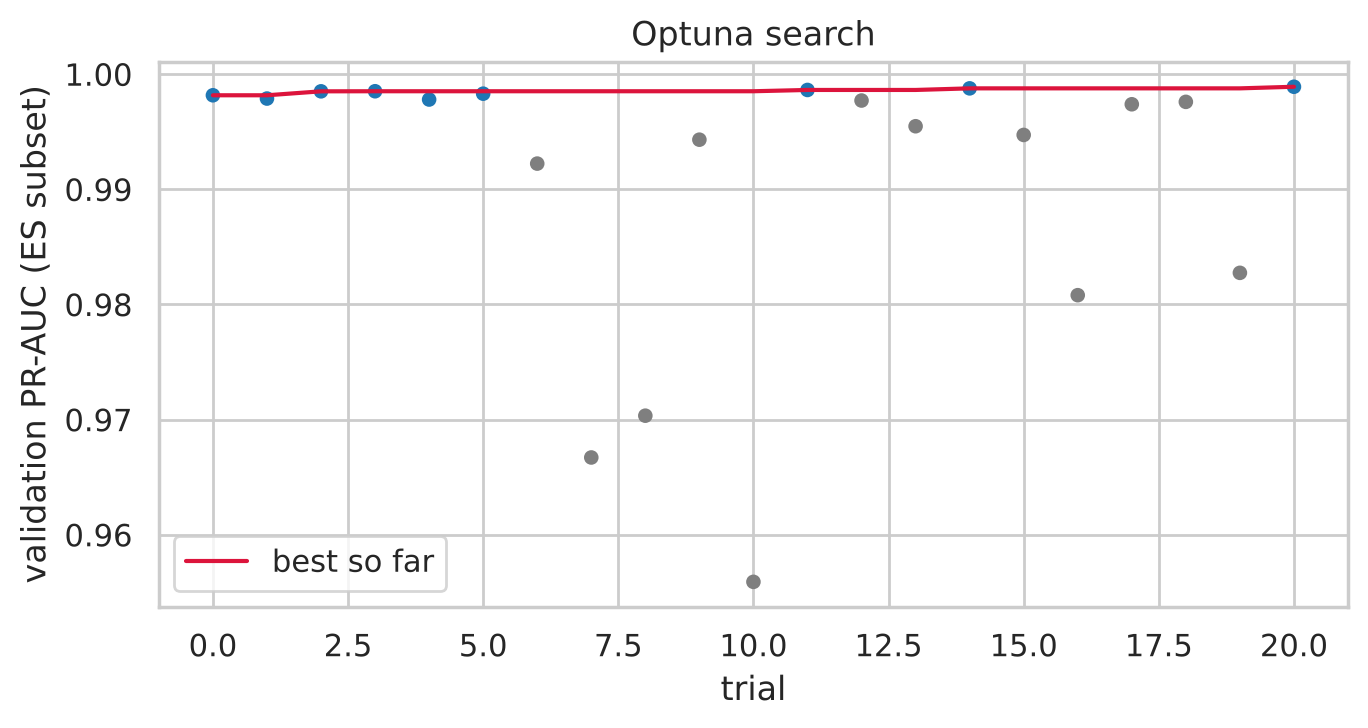

In [8]:
cal_best = calibration.sort_values(['PR-AUC', 'recall@P0.8'], ascending=False)
BEST_STRATEGY = cal_best.index[0]
print('strategy used for the search:', BEST_STRATEGY)
N_TRIALS, TIMEOUT = (2, 120) if QUICK else (30, 40 * 60)

def objective(trial):
    kw = {'lr': trial.suggest_float('lr', 3e-4, 5e-3, log=True),
          'weight_decay': trial.suggest_float('weight_decay', 1e-6, 1e-2, log=True),
          'dropout': trial.suggest_float('dropout', 0.0, 0.5),
          'lam': trial.suggest_categorical('lam', [0.25, 0.5, 1.0])}
    size = trial.suggest_categorical('size', [32, 64, 128])
    if BEST_ARCH in ('LSTM', 'GRU'):
        kw.update(hidden=size, layers=trial.suggest_int('layers', 1, 2))
    elif BEST_ARCH == 'TCN':
        kw.update(channels=size)
    else:
        kw.update(hidden=size, channels=max(16, size // 2))
    strat = Strategy(BEST_STRATEGY, TR.yb, TR.ym, 60000, neg_ratio=4, rep=5, seed=SEED + trial.number)
    _, hist = train_model(BEST_ARCH, BEST_L, TR, VA, strat, epochs=2 if QUICK else 6, patience=2, val_idx=val_es_idx,
                          seed=SEED, verbose=False, trial=trial, **kw)
    return hist['val_pr_auc'].max()

t0 = time.time()
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))
study.optimize(objective, n_trials=N_TRIALS, timeout=TIMEOUT)
trials = study.trials_dataframe(attrs=('number', 'value', 'state', 'params', 'duration'))
print(f'{len(trials)} trials in {(time.time() - t0) / 60:.1f} min; complete: {(trials.state == "COMPLETE").sum()}, pruned: {(trials.state == "PRUNED").sum()}')
print('best value', round(study.best_value, 4), 'params', study.best_params)
display(trials.sort_values('value', ascending=False).head(8).round(4))

fig, ax = plt.subplots(figsize=(7, 3.8))
ok = trials[trials['value'].notna()]
ax.scatter(ok['number'], ok['value'], c=np.where(ok['state'] == 'COMPLETE', 'tab:blue', 'tab:grey'), s=18)
ax.plot(ok['number'], ok['value'].cummax(), color='crimson', label='best so far')
ax.set_xlabel('trial'); ax.set_ylabel('validation PR-AUC (ES subset)'); ax.set_title('Optuna search'); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'optuna.png'), dpi=160); plt.show()

In [9]:
bp = dict(study.best_params)
size = bp.pop('size')
kw = {'lr': bp.pop('lr'), 'weight_decay': bp.pop('weight_decay'), 'dropout': bp.pop('dropout'), 'lam': bp.pop('lam')}
if BEST_ARCH in ('LSTM', 'GRU'):
    kw.update(hidden=size, layers=bp.pop('layers'))
elif BEST_ARCH == 'TCN':
    kw.update(channels=size)
else:
    kw.update(hidden=size, channels=max(16, size // 2))
name = f'{BEST_ARCH} L={BEST_L} {BEST_STRATEGY} (Optuna)'
strat = Strategy(BEST_STRATEGY, TR.yb, TR.ym, 60000, neg_ratio=4, rep=5, seed=SEED)
t0 = time.time()
tuned_model, hist = train_model(BEST_ARCH, BEST_L, TR, VA, strat, epochs=EPOCHS + (0 if QUICK else 4), patience=PATIENCE, val_idx=val_es_idx, seed=SEED, **kw)
pb, pm = predict(tuned_model, VA, BEST_L)
np.savez_compressed(os.path.join(RUN_DIR, 'tuned.npz'), pb=pb, pm=pm, hist=hist.to_dict(orient='list'), minutes=(time.time() - t0) / 60)
r, lead = evaluate(name, VA.yb, VA.ym, pb, pm, val_meta, failures)
r.update({'family': 'deep learning', 'architecture': BEST_ARCH, 'L': BEST_L, 'strategy': BEST_STRATEGY + ' + Optuna',
          'epochs_run': len(hist), 'best_epoch': int(hist['val_pr_auc'].idxmax()) + 1, 'train_minutes': (time.time() - t0) / 60})
results.append(r); histories[name] = hist; preds[name] = (pb, pm); leads[name] = lead
os.makedirs('models', exist_ok=True)
torch.save({'state_dict': tuned_model.state_dict(), 'arch': BEST_ARCH, 'L': BEST_L, 'kw': kw, 'norm_stats': norm_stats, 'age_stats': age_stats},
           os.path.join('models', 'week2_best.pt'))
print(name, {k: round(v, 4) if isinstance(v, float) else v for k, v in r.items() if k in ('PR-AUC', 'recall', 'F1_macro_comp', 'lead_median_h')})

  ep  1 loss 0.2117  val PR-AUC 0.9938  (12s)


  ep  2 loss 0.0357  val PR-AUC 0.9966  (10s)


  ep  3 loss 0.0278  val PR-AUC 0.9990  (11s)


  ep  4 loss 0.0206  val PR-AUC 0.9985  (12s)


  ep  5 loss 0.0167  val PR-AUC 0.9972  (12s)


  ep  6 loss 0.0158  val PR-AUC 0.9938  (12s)


TCN L=24 oversample (Optuna) {'PR-AUC': 0.9987, 'recall': 0.9992, 'F1_macro_comp': 0.8652, 'lead_median_h': np.float64(24.0)}


## Comparison on validation against the week-1 baseline

,model,L,strategy,PR-AUC,ROC-AUC,precision,recall,FP,F1_macro_comp,F1_macro_comp_direct,F1_comp1,F1_comp2,F1_comp3,F1_comp4,events,events_alerted_%,lead_median_h,lead_mean_h,Brier,ECE
0,XGBoost (week 1),NaN,class weights,0.9981,1.0000,0.8002,1.0000,662,0.8754,0.9928,0.9096,0.9545,0.7911,0.8465,112,100.00,24.0,25.1786,0.0007,0.0026
1,Logistic regression (week 1),NaN,class weights,0.8531,0.9977,0.8001,0.8043,533,0.7699,0.7498,0.6276,0.8783,0.7232,0.8507,112,93.75,24.0,24.1905,0.0158,0.0291
2,LSTM L=24,24.0,undersample,0.9966,0.9999,0.8002,0.9996,662,0.8670,0.9859,0.8452,0.9769,0.7474,0.8985,112,100.00,24.0,25.6429,0.0004,0.0004
3,TCN L=24,24.0,undersample,0.9989,1.0000,0.8000,1.0000,663,0.8742,0.9464,0.8293,0.9647,0.8667,0.8359,112,100.00,24.0,26.8571,0.0015,0.0025
4,CNN-LSTM L=24,24.0,undersample,0.9979,1.0000,0.8000,1.0000,663,0.8751,0.9597,0.7249,0.9991,0.9627,0.8137,112,100.00,24.0,24.7857,0.0010,0.0022
5,LSTM L=72,72.0,undersample,0.9915,0.9999,0.8000,1.0000,663,0.8717,0.9531,0.7793,0.9578,0.8950,0.8546,112,100.00,24.0,24.2946,0.0013,0.0014
6,TCN L=72,72.0,undersample,0.9989,1.0000,0.8002,0.9996,662,0.8757,0.9473,0.7652,0.9721,0.9064,0.8590,112,100.00,24.0,24.9464,0.0014,0.0026
7,CNN-LSTM L=72,72.0,undersample,0.9951,0.9999,0.8000,1.0000,663,0.8729,0.9453,0.7534,0.9609,0.8650,0.9122,112,100.00,24.0,24.6696,0.0016,0.0023
8,LSTM L=168,168.0,undersample,0.9927,0.9999,0.8000,1.0000,663,0.8914,0.9621,0.7483,0.8963,0.9649,0.9561,112,100.00,24.0,24.9464,0.0012,0.0015
9,TCN L=168,168.0,undersample,0.9993,1.0000,0.8000,1.0000,663,0.8679,0.9661,0.8078,0.9704,0.7860,0.9073,112,100.00,24.0,26.1071,0.0008,0.0012


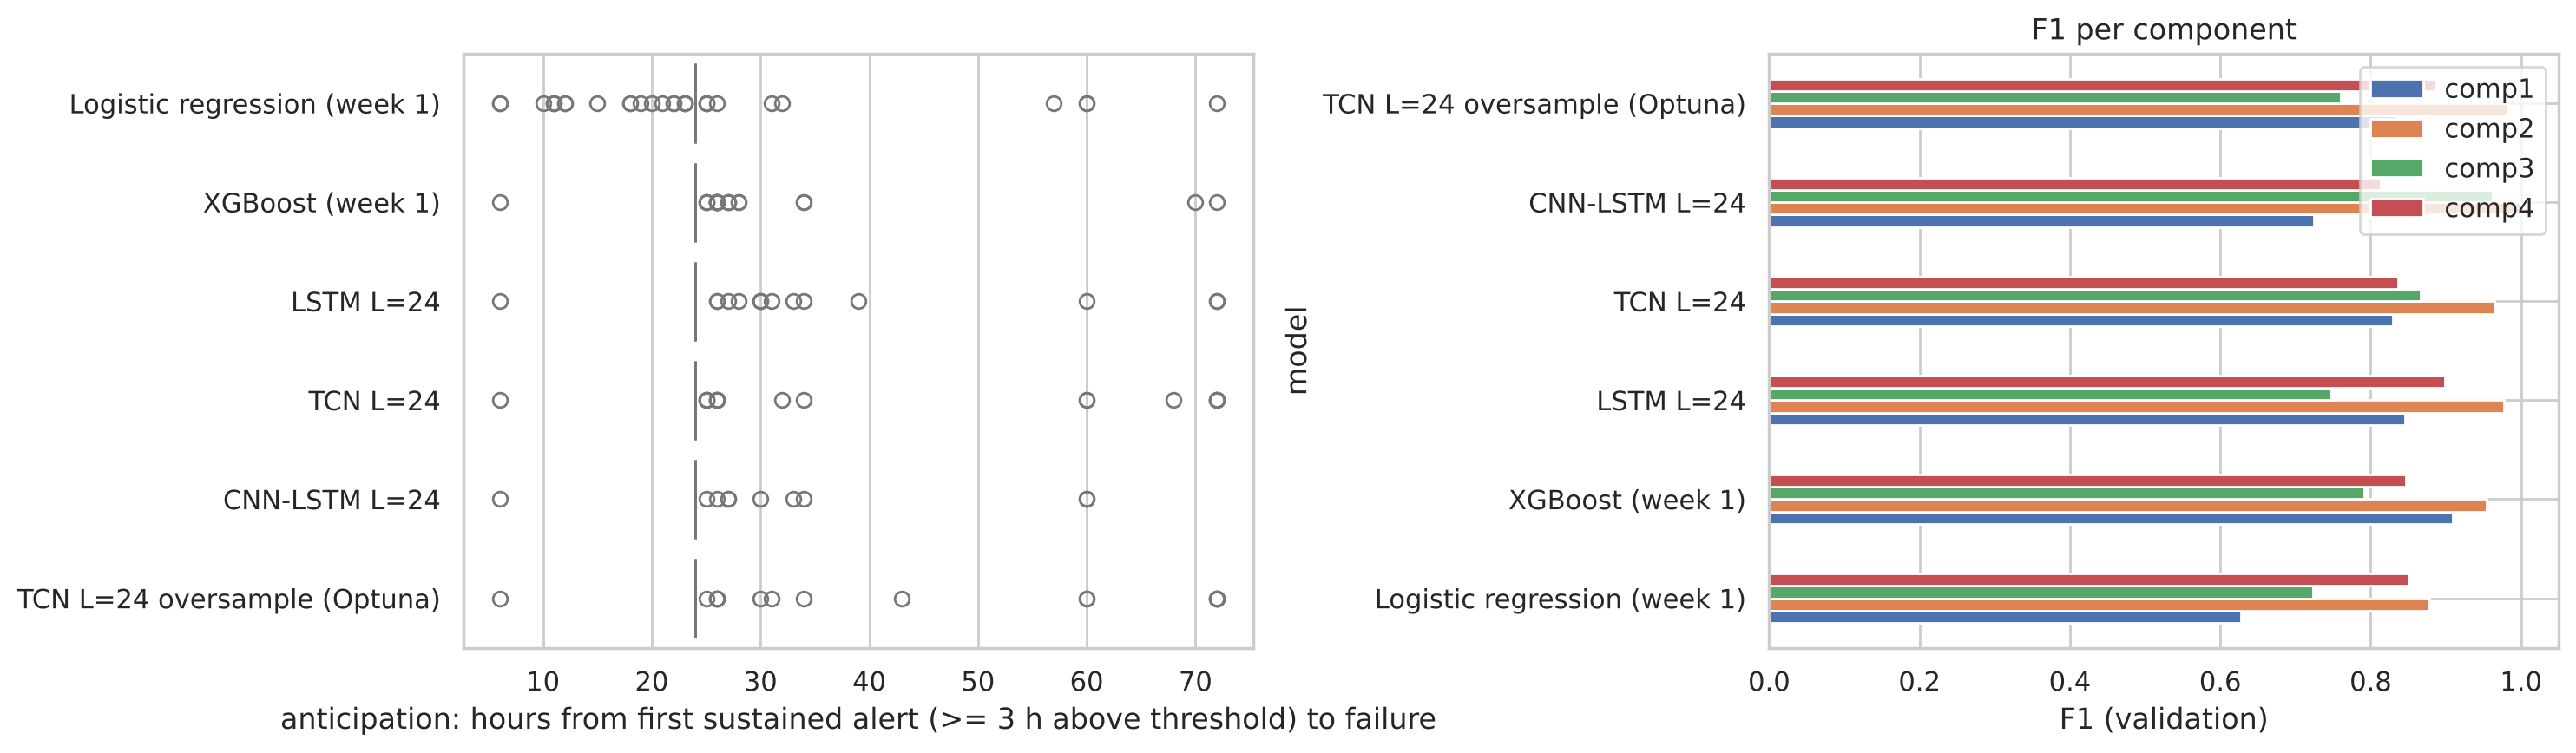

In [10]:
res = pd.DataFrame(results)
cols = ['model', 'L', 'strategy', 'PR-AUC', 'ROC-AUC', 'precision', 'recall', 'FP', 'F1_macro_comp', 'F1_macro_comp_direct',
        'F1_comp1', 'F1_comp2', 'F1_comp3', 'F1_comp4', 'events', 'events_alerted_%', 'lead_median_h', 'lead_mean_h', 'Brier', 'ECE']
comparison = res[cols].copy()
display(comparison.round(4))
comparison.to_csv(os.path.join(OUT_DIR, 'week2_validation_comparison.csv'), index=False)
calibration.to_csv(os.path.join(OUT_DIR, 'week2_calibration.csv'))
trials.to_csv(os.path.join(OUT_DIR, 'week2_optuna_trials.csv'), index=False)
pd.concat({k: v for k, v in histories.items()}, names=['run']).to_csv(os.path.join(OUT_DIR, 'week2_learning_curves.csv'))

final_models = ['Logistic regression (week 1)', 'XGBoost (week 1)'] + [f'{a} L={BEST_L}' for a in ARCHS] + [name]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
lead_df = pd.concat([leads[k].assign(model=k) for k in final_models], ignore_index=True)
sns.boxplot(data=lead_df, x='lead_hours', y='model', ax=axes[0], color='lightsteelblue')
axes[0].set_xlabel('anticipation: hours from first sustained alert (>= 3 h above threshold) to failure'); axes[0].set_ylabel('')
f1 = res.set_index('model').loc[final_models, ['F1_comp1', 'F1_comp2', 'F1_comp3', 'F1_comp4']]
f1.columns = COMPS
f1.plot(kind='barh', ax=axes[1]); axes[1].set_xlim(0, 1.05); axes[1].set_xlabel('F1 (validation)'); axes[1].set_title('F1 per component')
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, 'anticipation_f1.png'), dpi=160); plt.show()